In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [59]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer


In [22]:
df=pd.read_excel("/kaggle/input/datasets/hassanzeeshan/missing-employee-data/synthetic_employee_data.xlsx")

In [23]:
df.head()

,Age,Salary,Experience,Gender,Department
0,58.0,68880.50,15.0,Male,IT
1,24.0,65887.14,34.0,Male,Sales
2,45.0,56521.41,14.0,Male,Sales
3,30.0,51319.89,34.0,Female,IT
4,46.0,26871.87,0.0,Male,Marketing


In [24]:
df=pd.read_excel("/kaggle/input/datasets/hassanzeeshan/missing-employee-data/synthetic_employee_data.xlsx", usecols=('Gender', 'Department','Salary'))

In [25]:
df.head()

,Salary,Gender,Department
0,68880.50,Male,IT
1,65887.14,Male,Sales
2,56521.41,Male,Sales
3,51319.89,Female,IT
4,26871.87,Male,Marketing


In [26]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1020 entries, 0 to 1019
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Salary      1008 non-null   float64
 1   Gender      1009 non-null   object 
 2   Department  1013 non-null   object 
dtypes: float64(1), object(2)
memory usage: 24.0+ KB


In [27]:
df.isnull().mean()*100

Salary        1.176471
Gender        1.078431
Department    0.686275
dtype: float64

<Axes: xlabel='Gender'>

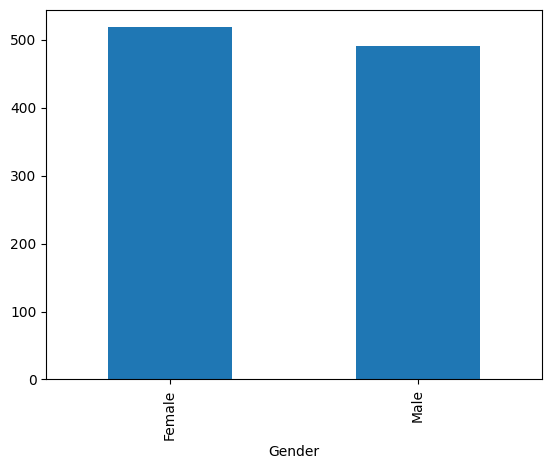

In [28]:
df['Gender'].value_counts().plot(kind='bar')

<Axes: xlabel='Department'>

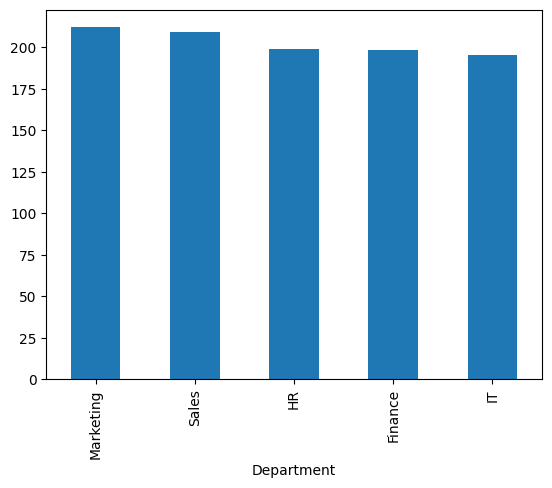

In [29]:
df['Department'].value_counts().plot(kind='bar')

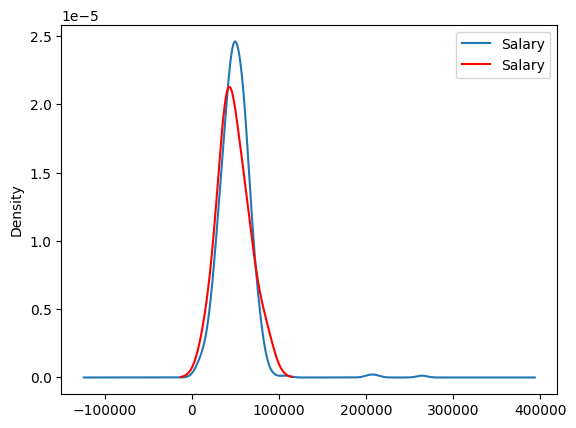

In [34]:
fig=plt.figure()
ax=fig.add_subplot(111)

df[df['Gender']=='Female']['Salary'].plot(kind='kde', ax=ax)

df[df['Gender'].isnull()]['Salary'].plot(kind='kde', ax=ax , color='red')

plt.legend()

In [35]:
temp=df[df['Gender']=='Female']['Salary']

In [36]:
df['Gender'].fillna('Female', inplace=True)

/tmp/ipykernel_58/3331058134.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Gender'].fillna('Female', inplace=True)


<Axes: xlabel='Gender'>

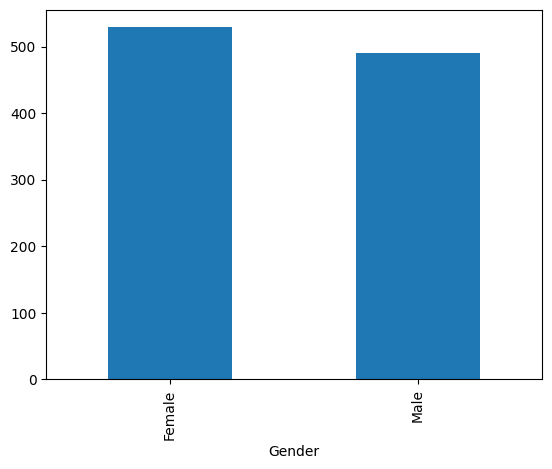

In [38]:
df['Gender'].value_counts().plot(kind='bar')

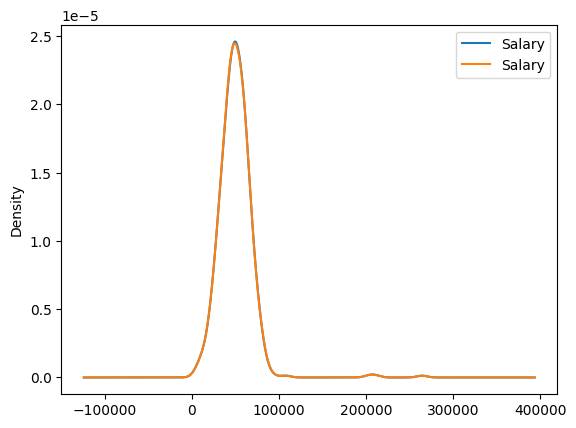

In [41]:
fig=plt.figure()
ax=fig.add_subplot(111)

temp.plot(kind='kde')

df[df['Gender']=='Female']['Salary'].plot(kind='kde', ax=ax)



plt.legend()

<Axes: xlabel='Department'>

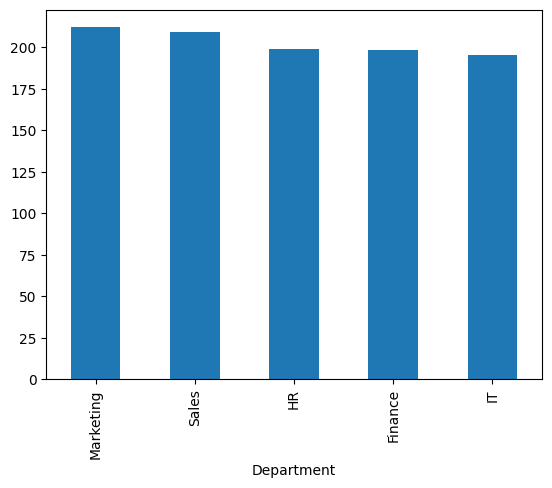

In [42]:
df['Department'].value_counts().plot(kind='bar')

In [44]:
df['Department'].value_counts()

Department
Marketing    212
Sales        209
HR           199
Finance      198
IT           195
Name: count, dtype: int64

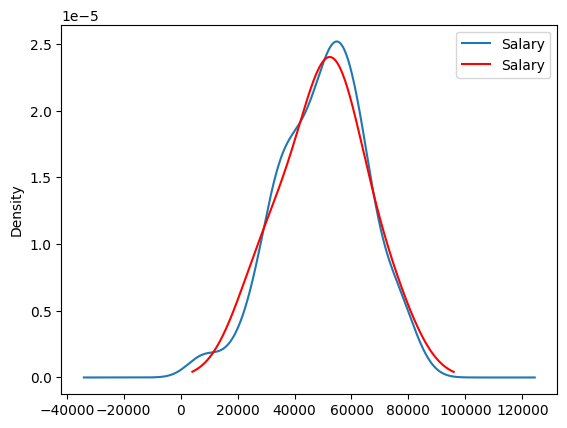

In [45]:
fig=plt.figure()
ax=fig.add_subplot(111)

df[df['Department']=='Marketing']['Salary'].plot(kind='kde', ax=ax)

df[df['Department'].isnull()]['Salary'].plot(kind='kde', ax=ax , color='red')

plt.legend()

In [46]:
temp=df[df['Department']=='Marketing']['Salary']

In [47]:
df['Department'].fillna('Marketing', inplace=True)

/tmp/ipykernel_58/1967646891.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Department'].fillna('Marketing', inplace=True)


<Axes: xlabel='Department'>

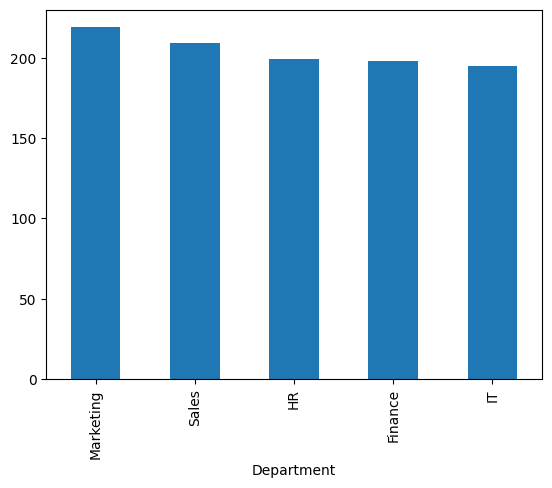

In [48]:
df['Department'].value_counts().plot(kind='bar')

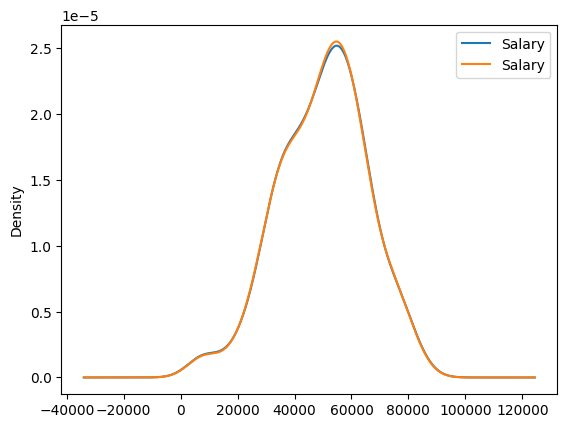

In [49]:
fig=plt.figure()
ax=fig.add_subplot(111)

temp.plot(kind='kde')

df[df['Department']=='Marketing']['Salary'].plot(kind='kde', ax=ax)



plt.legend()

In [51]:
X=df.drop(columns=['Salary'])
y=df['Salary']

In [52]:
X_train,X_test,Y_train,Y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [57]:
Y_test

523    55927.26
602    29957.62
526    46826.00
31     50499.44
616    38456.92
         ...   
516    70243.94
449    59924.75
783    46812.29
593    27081.46
909    43712.88
Name: Salary, Length: 204, dtype: float64

In [60]:
imputer=SimpleImputer(strategy='most_frequent')

In [63]:
X_train_imp=imputer.fit_transform(X_train)
X_test_imp=imputer.transform(X_test)

In [69]:
imputer.statistics_

array(['Female', 'Marketing'], dtype=object)